Heart Disease Prediction Using Machine Learning	Use cross-validation to ensure model generalization by manually splitting data into k-folds, training and testing models iteratively without using built-in cross-validation functions, and computing aggregated performance metrics.

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)
print("Total records:", len(df))

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Total records: 79


In [6]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def train_model(X, y, learning_rate=0.01, epochs=1000):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std[std == 0] = 1

    X_scaled = (X - mean) / std
    X_scaled = np.column_stack((np.ones(len(X_scaled)), X_scaled))

    weights = np.zeros(X_scaled.shape[1])

    for epoch in range(epochs):
        predictions = sigmoid(X_scaled @ weights)
        gradient = X_scaled.T @ (predictions - y) / len(y)
        weights -= learning_rate * gradient

    return weights, mean, std


def predict_model(X, weights, mean, std):
    std[std == 0] = 1
    X_scaled = (X - mean) / std
    X_scaled = np.column_stack((np.ones(len(X_scaled)), X_scaled))

    return (sigmoid(X_scaled @ weights) >= 0.5).astype(int)

In [7]:
np.random.seed(42)

indices = np.random.permutation(len(X))
folds = np.array_split(indices, 5)

results = []

for fold_number in range(5):
    test_indices = folds[fold_number]
    train_indices = np.concatenate([
        folds[i] for i in range(5) if i != fold_number
    ])

    X_train = X[train_indices]
    y_train = y[train_indices]
    X_test = X[test_indices]
    y_test = y[test_indices]

    weights, mean, std = train_model(X_train, y_train)
    predictions = predict_model(X_test, weights, mean, std)

    tp = np.sum((y_test == 1) & (predictions == 1))
    tn = np.sum((y_test == 0) & (predictions == 0))
    fp = np.sum((y_test == 0) & (predictions == 1))
    fn = np.sum((y_test == 1) & (predictions == 0))

    accuracy = (tp + tn) / len(y_test) * 100
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append([accuracy, precision * 100, recall * 100, f1 * 100])

    print("Fold:", fold_number + 1)
    print("Accuracy:", round(accuracy, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall:", round(recall * 100, 2), "%")
    print("F1-Score:", round(f1 * 100, 2), "%")
    print()

Fold: 1
Accuracy: 87.5 %
Precision: 84.62 %
Recall: 100.0 %
F1-Score: 91.67 %

Fold: 2
Accuracy: 87.5 %
Precision: 93.33 %
Recall: 93.33 %
F1-Score: 93.33 %

Fold: 3
Accuracy: 68.75 %
Precision: 66.67 %
Recall: 100.0 %
F1-Score: 80.0 %

Fold: 4
Accuracy: 87.5 %
Precision: 85.71 %
Recall: 100.0 %
F1-Score: 92.31 %

Fold: 5
Accuracy: 86.67 %
Precision: 86.67 %
Recall: 100.0 %
F1-Score: 92.86 %



In [8]:
results_df = pd.DataFrame(
    results,
    columns=["Accuracy", "Precision", "Recall", "F1-Score"]
)

print("Performance for Each Fold")
print(results_df.round(2).to_string(index=False))

print("\nAverage Performance Across 5 Folds")
print(results_df.mean().round(2))

print("\nMinimum Accuracy:", round(results_df["Accuracy"].min(), 2), "%")
print("Maximum Accuracy:", round(results_df["Accuracy"].max(), 2), "%")
print("Accuracy Standard Deviation:", round(results_df["Accuracy"].std(), 2))

Performance for Each Fold
 Accuracy  Precision  Recall  F1-Score
    87.50      84.62  100.00     91.67
    87.50      93.33   93.33     93.33
    68.75      66.67  100.00     80.00
    87.50      85.71  100.00     92.31
    86.67      86.67  100.00     92.86

Average Performance Across 5 Folds
Accuracy     83.58
Precision    83.40
Recall       98.67
F1-Score     90.03
dtype: float64

Minimum Accuracy: 68.75 %
Maximum Accuracy: 87.5 %
Accuracy Standard Deviation: 8.3


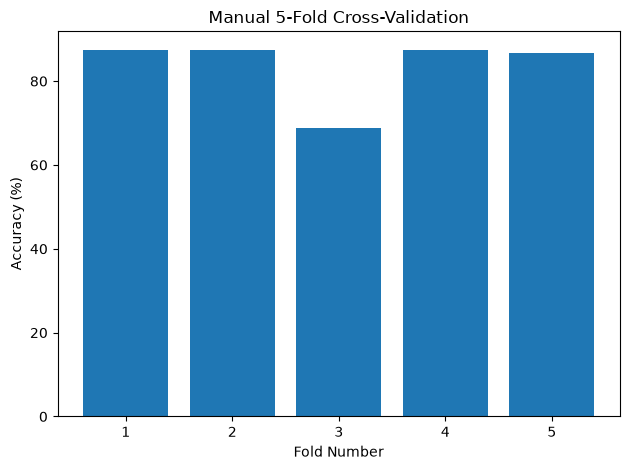

In [9]:
import matplotlib.pyplot as plt

plt.bar(
    range(1, 6),
    results_df["Accuracy"]
)

plt.xlabel("Fold Number")
plt.ylabel("Accuracy (%)")
plt.title("Manual 5-Fold Cross-Validation")
plt.xticks(range(1, 6))
plt.tight_layout()
plt.show()